# Experimento 1 · Filtrado colaborativo — usuarios con 3 a 4 películas mexicanas

Este grupo representa al **espectador ocasional** de cine mexicano: reseñó solo 3 o 4 películas mexicanas. Con la partición, en entrenamiento le quedan 1 o 2 películas mexicanas, más su historial reciente de cine en general (~80 películas). Es un escenario cercano al *arranque en frío* dentro del dominio: el sistema tiene que inferir qué cine mexicano le gustará apoyándose sobre todo en lo que ve fuera de él.

**Pregunta.** ¿Qué tan bien recomienda cine mexicano un filtrado colaborativo entrenado con el historial de estos usuarios, y mejora si la señal de preferencia incorpora el sentimiento de sus reseñas?

**Protocolo** (detalle en `docs/Protocolo_y_metricas.md`):
1. Ajuste de hiperparámetros: entrenar con `train`, medir en `val` (criterio nDCG@10; RMSE para predicción).
2. Evaluación final: reentrenar con `train + val` y medir **una sola vez** en `test`.
3. Relevante = película mexicana retenida calificada con **≥ 3.5 ★**. Se ordena todo el catálogo mexicano (878 películas) menos lo ya visto.

| Variante | Señal de preferencia | Requiere |
|---|---|---|
| **A** | solo estrellas / *like* (línea base) | — (se ejecuta aquí) |
| **B** | estrellas + sentimiento **BETO** | `datos/limpios/sentimiento/sentimiento_beto.parquet` (notebook 04) |
| **C** | estrellas + sentimiento **JEV** (LLM) | `datos/limpios/sentimiento/sentimiento_jev.parquet` (notebook 05) |

Si los archivos de B o C no existen, el notebook corre solo la variante A y lo indica. Después de ejecutar 04 y/o 05, basta con volver a correr este notebook completo.

In [1]:
# --- Configuración del entorno ---------------------------------------------
# En la Mac no hay que cambiar nada. En Colab u otro servidor: sube la carpeta
# TT_Recomendador_Cine_Mexicano (basta con src/ y datos/limpios/) y descomenta:
# from google.colab import drive
# drive.mount('/content/drive')
# import os; os.environ['TT_RAIZ'] = '/content/drive/MyDrive/TT_Recomendador_Cine_Mexicano'

import os, sys, warnings
from pathlib import Path
RAIZ = Path(os.environ.get('TT_RAIZ', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))
os.environ['TT_RAIZ'] = str(RAIZ)
sys.path.insert(0, str(RAIZ / 'src'))
warnings.filterwarnings('ignore', category=FutureWarning)
print('Raíz del proyecto:', RAIZ)

Raíz del proyecto: /Users/irving/Documents/TrabajoTerminal/TT_Recomendador_Cine_Mexicano


In [2]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from recomendador import rutas, senal, metricas as M, modelos_cf as cf, experimento as E

GRUPO = 'g34'
EXP = rutas.GRUPOS[GRUPO]['experimento']
SALIDA = rutas.carpeta_resultados(EXP)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

cat = E.cargar_catalogo()
catalogo = pd.Index(cat['item'])
inter = E.cargar_interacciones(GRUPO)
print(rutas.GRUPOS[GRUPO]['nombre'], '→ resultados en', SALIDA)

Usuarios con 3 a 4 películas mexicanas reseñadas → resultados en /Users/irving/Documents/TrabajoTerminal/TT_Recomendador_Cine_Mexicano/resultados/exp1


## 1. Datos del grupo

In [3]:
mx = inter[inter.es_mx]
descripcion = pd.Series({
    'usuarios': inter.usuario.nunique(),
    'películas (todas)': inter['item'].nunique(),
    'películas del catálogo mexicano vistas': mx['item'].nunique(),
    'interacciones': len(inter),
    'densidad de la matriz (%)': 100 * len(inter) / (inter.usuario.nunique() * inter['item'].nunique()),
    'interacciones con cine mexicano': len(mx),
    '  …de ellas con reseña escrita': int(mx.tiene_resena.sum()),
    'pares en train': int((inter.particion == 'train').sum()),
    'pares en val': int((inter.particion == 'val').sum()),
    'pares en test': int((inter.particion == 'test').sum()),
    'test relevantes (≥ 3.5 ★)': int(((inter.particion == 'test') & (inter.calificacion >= 3.5)).sum()),
    'usuarios evaluables en test (≥1 relevante)': inter[(inter.particion == 'test') & (inter.calificacion >= 3.5)].usuario.nunique(),
}, name='valor')
descripcion.to_csv(SALIDA / 'descripcion_datos.csv')
descripcion.to_frame()

,valor
usuarios,19790.0000
películas (todas),72240.0000
películas del catálogo mexicano vistas,828.0000
interacciones,1659339.0000
densidad de la matriz (%),0.1161
interacciones con cine mexicano,95799.0000
…de ellas con reseña escrita,66339.0000
pares en train,1621906.0000
pares en val,18335.0000
pares en test,19098.0000


## 2. Señal de preferencia — variante A

Cada par usuario–película se convierte en una preferencia `p ∈ [0, 1]`:

| Caso | p |
|---|---|
| tiene estrellas | estrellas / 5 |
| sin estrellas, con *like* | 0.9 (≈ 4.5 ★) |
| sin estrellas ni *like* | 0.6 (≈ 3 ★: la vio, no sabemos más) |

Los modelos de predicción de calificación usan las estrellas directamente (`calif_efectiva`).

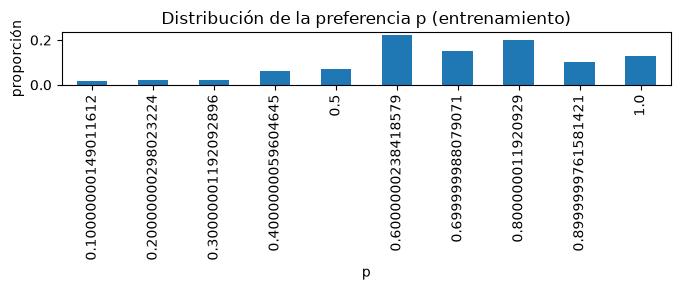

In [4]:
fig, eje = plt.subplots(figsize=(7, 3))
inter.loc[inter.particion != 'test', 'p'].round(2).value_counts(normalize=True).sort_index().plot.bar(ax=eje)
eje.set(title='Distribución de la preferencia p (entrenamiento)', xlabel='p', ylabel='proporción')
fig.tight_layout()

## 3. Modelos y rejillas de hiperparámetros

**Ranking (top-N)** — puntúan las 878 películas del catálogo mexicano:

| Modelo | Idea | Hiperparámetro |
|---|---|---|
| Popularidad | lo más visto en entrenamiento; referencia mínima | — |
| ItemKNN | "quienes vieron lo que tú viste también vieron…"; coseno entre columnas | vecinos *k* |
| PureSVD | factorización SVD truncada (aleatorizada) de la matriz de preferencias | número de factores |
| EASE | autoencoder lineal con solución cerrada; aprende cuánto aporta cada película vista a cada candidata (usa las películas con ≥ 20 interacciones + todo el catálogo mexicano) | regularización λ |

**Predicción de calificación** — estiman las estrellas de las películas retenidas: media global, sesgos (μ + b_u + b_i) y vecinos sobre residuales (ItemKNN con sesgos).

In [5]:
FAMILIAS = {
    'Popularidad': (lambda p: cf.Popularidad(), [{}]),
    'ItemKNN':     (lambda p: cf.ItemKNN(**p), [{'k': k} for k in (10, 25, 50, 100, 400, 1600, 6400)]),
    'PureSVD':     (lambda p: cf.PureSVD(**p), [{'factores': f} for f in (64, 128, 256, 384, 512, 768)]),
    'EASE':        (lambda p: cf.EASE(**p), [{'lam': l, 'min_interacciones': 20} for l in (25, 50, 100, 250, 500)]),
}
FAMILIAS_RATING = {
    'MediaGlobal':   (lambda p: cf.MediaGlobal(), [{}]),
    'Sesgos':        (lambda p: cf.Sesgos(**p), [{'reg_item': a, 'reg_usuario': b} for a, b in ((2, 5), (5, 10), (10, 15))]),
    'ItemKNNSesgos': (lambda p: cf.ItemKNNSesgos(**p), [{'k': 40, 'shrink': s, 'reg': r, 'reg_item': 2, 'reg_usuario': 5}
                                                        for s in (20, 100) for r in (0.5, 1.0)]),
}

## 4. Ajuste de hiperparámetros en validación

In [6]:
t0 = time.time()
tabla_val, mejores = E.ajustar(inter, catalogo, FAMILIAS)
print(f'\nMejores hiperparámetros: {mejores}   ({time.time()-t0:.0f} s)')
tabla_val.to_csv(SALIDA / 'ajuste_validacion_ranking.csv', index=False)

Validación: 10,854 usuarios con al menos un relevante
  Popularidad        {}                                       nDCG@10=0.0248


  ItemKNN            {'k': 10}                                nDCG@10=0.0506


  ItemKNN            {'k': 25}                                nDCG@10=0.0489


  ItemKNN            {'k': 50}                                nDCG@10=0.0483


  ItemKNN            {'k': 100}                               nDCG@10=0.0476


  ItemKNN            {'k': 400}                               nDCG@10=0.0482


... (8 outputs left out)

  EASE               {'lam': 50, 'min_interacciones': 20}     nDCG@10=0.1007


  EASE               {'lam': 100, 'min_interacciones': 20}    nDCG@10=0.1019


  EASE               {'lam': 250, 'min_interacciones': 20}    nDCG@10=0.0989


  EASE               {'lam': 500, 'min_interacciones': 20}    nDCG@10=0.0947

Mejores hiperparámetros: {'Popularidad': {}, 'ItemKNN': {'k': 6400}, 'PureSVD': {'factores': 512}, 'EASE': {'lam': 100, 'min_interacciones': 20}}   (85 s)


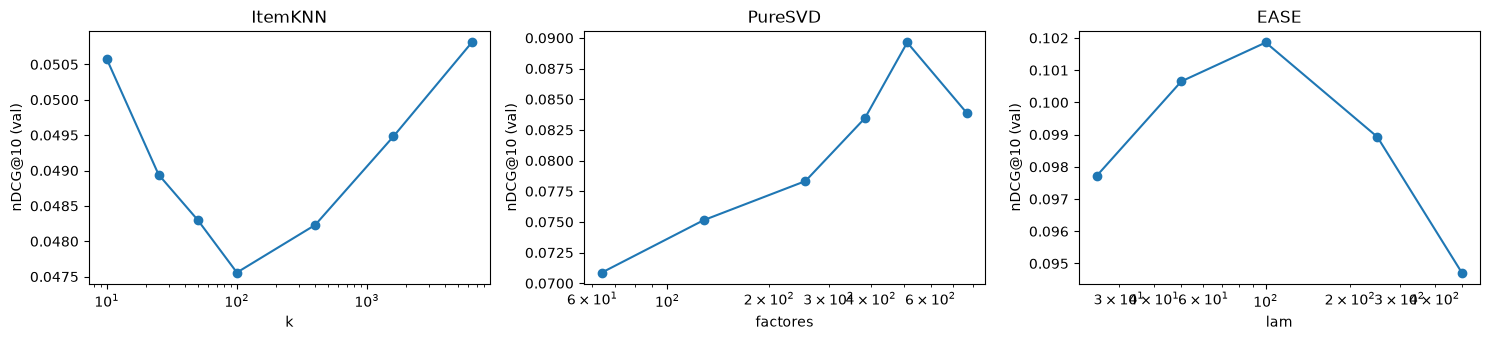

In [7]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 3.5))
for eje, (nombre, clave) in zip(ejes, [('ItemKNN', 'k'), ('PureSVD', 'factores'), ('EASE', 'lam')]):
    t = tabla_val[tabla_val.modelo == nombre].copy()
    t['x'] = t.params.map(lambda s: eval(s)[clave])
    eje.plot(t.x, t['nDCG@10'], 'o-')
    eje.set(title=nombre, xlabel=clave, ylabel='nDCG@10 (val)', xscale='log')
fig.tight_layout(); fig.savefig(SALIDA / 'ajuste_validacion_ranking.png', dpi=130)

In [8]:
tabla_val_rating, mejores_rating = E.ajustar_rating(inter, catalogo, FAMILIAS_RATING)
print('\nMejores:', mejores_rating)
tabla_val_rating.to_csv(SALIDA / 'ajuste_validacion_rating.csv', index=False)
MODELOS_RATING = E.constructores(FAMILIAS_RATING, mejores_rating)

  MediaGlobal    {}                                                      RMSE=1.1343
  Sesgos         {'reg_item': 2, 'reg_usuario': 5}                       RMSE=0.8738


  Sesgos         {'reg_item': 5, 'reg_usuario': 10}                      RMSE=0.8775
  Sesgos         {'reg_item': 10, 'reg_usuario': 15}                     RMSE=0.8852


  ItemKNNSesgos  {'k': 40, 'shrink': 20, 'reg': 0.5, 'reg_item': 2, 'reg_usuario': 5} RMSE=0.8707


  ItemKNNSesgos  {'k': 40, 'shrink': 20, 'reg': 1.0, 'reg_item': 2, 'reg_usuario': 5} RMSE=0.8717


  ItemKNNSesgos  {'k': 40, 'shrink': 100, 'reg': 0.5, 'reg_item': 2, 'reg_usuario': 5} RMSE=0.8718


  ItemKNNSesgos  {'k': 40, 'shrink': 100, 'reg': 1.0, 'reg_item': 2, 'reg_usuario': 5} RMSE=0.8725

Mejores: {'MediaGlobal': {}, 'Sesgos': {'reg_item': 2, 'reg_usuario': 5}, 'ItemKNNSesgos': {'k': 40, 'shrink': 20, 'reg': 0.5, 'reg_item': 2, 'reg_usuario': 5}}


## 5. Evaluación final en prueba — variante A (solo estrellas)

In [9]:
similitud = E.similitud_catalogo(cat)   # para la diversidad intra-lista (ILD)
t0 = time.time()
A = E.evaluar_test(inter, catalogo, FAMILIAS, mejores, 'A', similitud, MODELOS_RATING)
print(f'{A["ranking"].usuarios_evaluados.iloc[0]:,} usuarios evaluados  ({time.time()-t0:.0f} s)')
cols = ['modelo'] + [f'{m}@{k}' for k in (5, 10, 20) for m in ('Precision', 'Recall', 'nDCG', 'HitRate')] + ['MAP@10', 'MRR@10']
A['ranking'][cols].set_index('modelo')

11,276 usuarios evaluados  (29 s)


,Precision@5,Recall@5,nDCG@5,HitRate@5,Precision@10,Recall@10,nDCG@10,HitRate@10,Precision@20,Recall@20,nDCG@20,HitRate@20,MAP@10,MRR@10
modelo,,,,,,,,,,,,,,
Popularidad,0.0056,0.0278,0.0154,0.0278,0.0064,0.0638,0.0269,0.0638,0.0064,0.1274,0.0427,0.1274,0.0160,0.0160
ItemKNN,0.0131,0.0654,0.0376,0.0654,0.0128,0.1281,0.0576,0.1281,0.0120,0.2402,0.0857,0.2402,0.0366,0.0366
PureSVD,0.0267,0.1337,0.0905,0.1337,0.0204,0.2043,0.1132,0.2043,0.0150,0.3005,0.1375,0.3005,0.0857,0.0857
EASE,0.0341,0.1705,0.1090,0.1705,0.0259,0.2591,0.1374,0.2591,0.0191,0.3828,0.1686,0.3828,0.1004,0.1004


In [10]:
# Más allá de la precisión: ¿recomienda siempre lo mismo? ¿lo obvio? ¿listas variadas?
A['ranking'].set_index('modelo')[['Cobertura@10', 'Novedad@10', 'ILD@10', 'Cobertura@20', 'Novedad@20', 'ILD@20']]

,Cobertura@10,Novedad@10,ILD@10,Cobertura@20,Novedad@20,ILD@20
modelo,,,,,,
Popularidad,0.0239,4.1919,0.9629,0.0433,4.5234,0.9639
ItemKNN,0.3360,4.7006,0.9692,0.4772,5.0361,0.9682
PureSVD,0.2677,5.7152,0.9681,0.3508,5.8324,0.9687
EASE,0.3770,5.3326,0.9656,0.5159,5.6118,0.9667


In [11]:
A['rating'].set_index('modelo')

,variante,RMSE,MAE,n
modelo,,,,
MediaGlobal,A,1.1330,0.8929,19098
Sesgos,A,0.8695,0.6682,19098
ItemKNNSesgos,A,0.8635,0.6629,19098


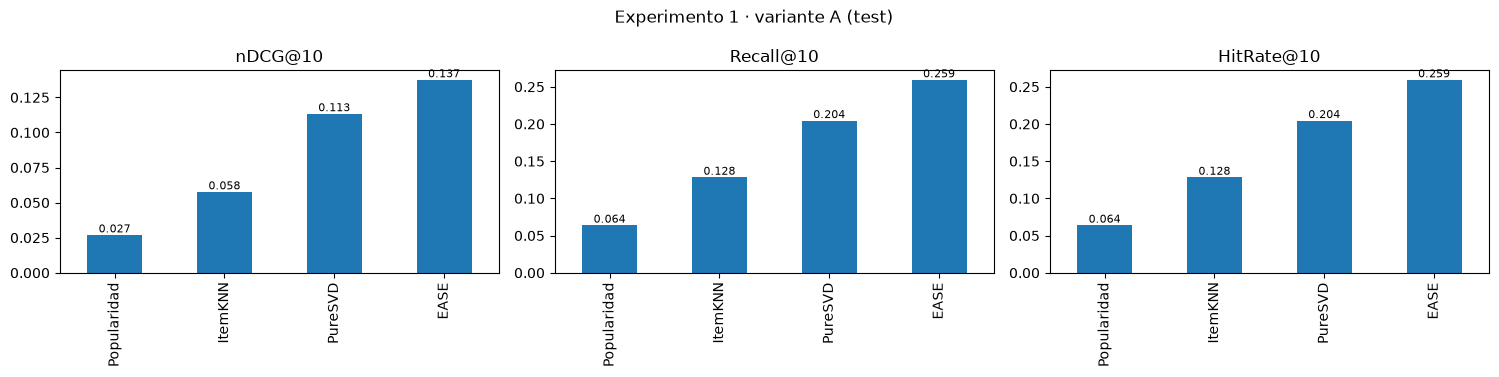

In [12]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
r = A['ranking'].set_index('modelo')
for eje, met in zip(ejes, ['nDCG@10', 'Recall@10', 'HitRate@10']):
    r[met].plot.bar(ax=eje, color='tab:blue')
    eje.set(title=met, xlabel='')
    for x, v in enumerate(r[met]): eje.text(x, v, f'{v:.3f}', ha='center', va='bottom', fontsize=8)
fig.suptitle(f'Experimento {EXP[-1]} · variante A (test)')
fig.tight_layout(); fig.savefig(SALIDA / 'metricas_test_variante_A.png', dpi=130)

## 6. Ejemplos de recomendaciones

Top-10 del mejor modelo para tres usuarios al azar. `relevante_en_test = True` marca la película que el usuario efectivamente vio y calificó con ≥ 3.5 ★ (y que el modelo no conocía).

In [13]:
mejor_modelo = A['ranking'].set_index('modelo')['nDCG@10'].idxmax()
print('Mejor modelo en test (variante A):', mejor_modelo)
E.ejemplos_recomendacion(A, cat, inter, mejor_modelo, n_usuarios=3, n=10)

Mejor modelo en test (variante A): EASE


,usuario,posicion,pelicula,relevante_en_test
0,victoriamedrano,1,I Am Frankelda,False
1,victoriamedrano,2,The Legend of La Llorona,False
2,victoriamedrano,3,Like or Die,False
3,victoriamedrano,4,Facing El Chapo,False
4,victoriamedrano,5,Pedro Páramo,False
5,victoriamedrano,6,Counterattack,False
6,victoriamedrano,7,Corina,False
7,victoriamedrano,8,Mexico 86,False
8,victoriamedrano,9,Lucca's World,False
9,victoriamedrano,10,The Legend of the Guanajuato Mummies,False


## 7. Variantes con sentimiento — B (BETO) y C (JEV)

Solo cambia la preferencia de las películas mexicanas que el usuario **reseñó en español** (son las únicas con texto). Con `s ∈ [-1, 1]` y `r_s = 3 + 2·s`:

* con estrellas: `p = λ·(estrellas/5) + (1 − λ)·(r_s/5)`
* sin estrellas: `p = r_s/5` (el sentimiento sustituye a la imputación fija de 0.6/0.9)

λ ∈ {0, 0.25, 0.5, 0.75, 1} se elige en validación por modelo, con los hiperparámetros ya fijados en la variante A. Popularidad no usa `p`, así que no se incluye.

In [14]:
FAMILIAS_SENT = {n: f for n, f in FAMILIAS.items() if n != 'Popularidad'}
disponibles = E.analizadores_disponibles()
CODIGO = {'beto': 'B', 'jev': 'C'}
variantes = {}
for analizador in ('beto', 'jev'):
    if analizador not in disponibles:
        print(f'[{CODIGO[analizador]}] {analizador.upper()}: no se encontró {rutas.ANALIZADORES[analizador].name}; '
              f'ejecuta el notebook {"04" if analizador == "beto" else "05"} y vuelve a correr este.')
        continue
    sent = E.cargar_sentimiento(analizador)
    variantes[CODIGO[analizador]] = E.variante_sentimiento(
        inter, sent, catalogo, FAMILIAS_SENT, mejores, CODIGO[analizador], similitud, MODELOS_RATING)

[B] BETO: no se encontró sentimiento_beto.parquet; ejecuta el notebook 04 y vuelve a correr este.
[C] JEV: no se encontró sentimiento_jev.parquet; ejecuta el notebook 05 y vuelve a correr este.


In [15]:
if variantes:
    val = pd.concat([v['validacion'] for v in variantes.values()])
    val.to_csv(SALIDA / 'ajuste_lambda_validacion.csv', index=False)
    fig, ejes = plt.subplots(1, 2, figsize=(13, 3.8))
    for (var, modelo), t in val[val['nDCG@10'].notna()].groupby(['variante', 'modelo']):
        ejes[0].plot(t['lambda'], t['nDCG@10'], 'o-', label=f'{var} · {modelo}')
    for (var, modelo), t in val[val['RMSE'].notna()].groupby(['variante', 'modelo']):
        ejes[1].plot(t['lambda'], t['RMSE'], 'o-', label=f'{var} · {modelo}')
    ejes[0].set(title='Ranking: nDCG@10 en val según λ', xlabel='λ (1 = solo estrellas)')
    ejes[1].set(title='Predicción: RMSE en val según λ', xlabel='λ (1 = solo estrellas)')
    for e in ejes: e.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(SALIDA / 'ajuste_lambda_validacion.png', dpi=130)
    display(pd.DataFrame({v: r['cobertura'] for v, r in variantes.items()}))
    display(pd.DataFrame({v: r['lambda_ranking'] | r['lambda_rating'] for v, r in variantes.items()}).rename_axis('λ elegido'))
else:
    print('Sin variantes de sentimiento todavía: solo se reporta la variante A.')

Sin variantes de sentimiento todavía: solo se reporta la variante A.


## 8. Comparación entre variantes y significancia estadística

La prueba de Wilcoxon pareada compara, usuario por usuario, el nDCG@10 de cada variante contra la línea base A. Un valor p < 0.05 indica que la diferencia no se explica por azar.

In [16]:
ranking = pd.concat([A['ranking']] + [v['ranking'] for v in variantes.values()], ignore_index=True)
rating = pd.concat([A['rating']] + [v['rating'] for v in variantes.values()], ignore_index=True)
por_usuario = pd.concat([A['por_usuario']] + [v['por_usuario'] for v in variantes.values()], ignore_index=True)
rating_detalle = pd.concat([A['rating_detalle']] + [v['rating_detalle'] for v in variantes.values()], ignore_index=True)

tabla = ranking.pivot_table(index='modelo', columns='variante', values=['nDCG@10', 'Recall@10', 'HitRate@10'])
display(tabla)
display(rating.pivot_table(index='modelo', columns='variante', values=['RMSE', 'MAE']))

significancia = pd.concat([E.comparar_variantes(por_usuario, 'A', m) for m in ('nDCG@10', 'Recall@10')], ignore_index=True)
significancia

,HitRate@10,Recall@10,nDCG@10
variante,A,A,A
modelo,,,
EASE,0.2591,0.2591,0.1374
ItemKNN,0.1281,0.1281,0.0576
Popularidad,0.0638,0.0638,0.0269
PureSVD,0.2043,0.2043,0.1132


,MAE,RMSE
variante,A,A
modelo,,
ItemKNNSesgos,0.6629,0.8635
MediaGlobal,0.8929,1.1330
Sesgos,0.6682,0.8695


,modelo,variante,metrica,usuarios,media_A,media_variante,diferencia,mejora_relativa,usuarios_mejoran,usuarios_empeoran,p_valor,significativo_5%


## 9. Guardado de resultados

In [17]:
ranking.to_csv(SALIDA / 'ranking_test.csv', index=False)
rating.to_csv(SALIDA / 'rating_test.csv', index=False)
por_usuario.to_parquet(SALIDA / 'por_usuario_test.parquet', index=False)
rating_detalle.to_parquet(SALIDA / 'rating_detalle_test.parquet', index=False)
significancia.to_csv(SALIDA / 'significancia.csv', index=False)
with open(SALIDA / 'hiperparametros.json', 'w') as f:
    json.dump({'ranking': mejores, 'rating': mejores_rating,
               'lambda': {v: {'ranking': r['lambda_ranking'], 'rating': r['lambda_rating']} for v, r in variantes.items()}},
              f, indent=2, default=float)
print('Guardado en', SALIDA)
sorted(p.name for p in SALIDA.iterdir())

Guardado en /Users/irving/Documents/TrabajoTerminal/TT_Recomendador_Cine_Mexicano/resultados/exp1


['ajuste_validacion_ranking.csv',
 'ajuste_validacion_ranking.png',
 'ajuste_validacion_rating.csv',
 'descripcion_datos.csv',
 'hiperparametros.json',
 'metricas_test_variante_A.png',
 'por_usuario_test.parquet',
 'ranking_test.csv',
 'rating_detalle_test.parquet',
 'rating_test.csv',
 'significancia.csv']

## 10. Lectura de resultados

In [18]:
r = ranking.set_index(['modelo', 'variante'])
mejor = r.xs('A', level='variante')['nDCG@10'].idxmax()
pop = r.loc[('Popularidad', 'A')]
best = r.loc[(mejor, 'A')]
print(f"Mejor modelo (variante A): {mejor}  ·  nDCG@10 = {best['nDCG@10']:.4f}  ·  Recall@10 = {best['Recall@10']:.4f}  ·  HitRate@10 = {best['HitRate@10']:.4f}")
print(f"Frente a Popularidad: nDCG@10 ×{best['nDCG@10']/pop['nDCG@10']:.1f}, Recall@10 ×{best['Recall@10']/pop['Recall@10']:.1f}")
print(f"En {best['HitRate@10']:.1%} de los usuarios, una película que le gustó aparece entre las 10 primeras de 878.")
for _, fila in significancia[significancia.metrica == 'nDCG@10'].iterrows():
    signo = 'mejora' if fila.diferencia > 0 else 'empeora'
    print(f"[{fila.variante}] {fila.modelo}: {signo} nDCG@10 en {fila.mejora_relativa:+.1%} "
          f"(p = {fila.p_valor:.3g}; {'significativo' if fila['significativo_5%'] else 'no significativo'} al 5 %)")

Mejor modelo (variante A): EASE  ·  nDCG@10 = 0.1374  ·  Recall@10 = 0.2591  ·  HitRate@10 = 0.2591
Frente a Popularidad: nDCG@10 ×5.1, Recall@10 ×4.1
En 25.9% de los usuarios, una película que le gustó aparece entre las 10 primeras de 878.
